In [ ]:
# Cell 1: Install ultralytics (YOLOv8) and supporting packages
!pip install -U ultralytics --quiet
# OpenCV is useful for reading images
!pip install opencv-python-headless --quiet


In [ ]:
# Cell 2: imports and quick GPU check
from ultralytics import YOLO
import os
import sys

# Print Python and ultralytics version for reproducibility / debugging
import importlib
print("Python:", sys.version.splitlines()[0])
try:
    import ultralytics
    print("ultralytics version:", ultralytics.__version__)
except Exception as e:
    print("ultralytics import error:", e)

# Check GPU availability (Colab: should show a GPU if one is attached)
try:
    import torch
    print("Torch CUDA available:", torch.cuda.is_available(), " | CUDA device count:", torch.cuda.device_count())
except Exception:
    print("PyTorch not available in this env (ultralytics may still work).")


Python: 3.12.13 (main, Mar  4 2026, 09:23:07) [GCC 11.4.0]
ultralytics version: 8.4.51
Torch CUDA available: True  | CUDA device count: 1


In [ ]:
# Cell 5: Load segmentation pretrained model (no inference/drawing here)
# We just instantiate it so students understand which backbone we're fine-tuning from.
seg_pretrained = "yolov8n-seg.pt"  # change to yolov8m-seg.pt / yolov8l-seg.pt for larger models
model = YOLO(seg_pretrained)
print("Loaded model:", seg_pretrained)
print("Model names (class id -> label) available:", getattr(model, "names", None))


Loaded model: yolov8n-seg.pt
Model names (class id -> label) available: {0: 'person', 1: 'bicycle', 2: 'car', 3: 'motorcycle', 4: 'airplane', 5: 'bus', 6: 'train', 7: 'truck', 8: 'boat', 9: 'traffic light', 10: 'fire hydrant', 11: 'stop sign', 12: 'parking meter', 13: 'bench', 14: 'bird', 15: 'cat', 16: 'dog', 17: 'horse', 18: 'sheep', 19: 'cow', 20: 'elephant', 21: 'bear', 22: 'zebra', 23: 'giraffe', 24: 'backpack', 25: 'umbrella', 26: 'handbag', 27: 'tie', 28: 'suitcase', 29: 'frisbee', 30: 'skis', 31: 'snowboard', 32: 'sports ball', 33: 'kite', 34: 'baseball bat', 35: 'baseball glove', 36: 'skateboard', 37: 'surfboard', 38: 'tennis racket', 39: 'bottle', 40: 'wine glass', 41: 'cup', 42: 'fork', 43: 'knife', 44: 'spoon', 45: 'bowl', 46: 'banana', 47: 'apple', 48: 'sandwich', 49: 'orange', 50: 'broccoli', 51: 'carrot', 52: 'hot dog', 53: 'pizza', 54: 'donut', 55: 'cake', 56: 'chair', 57: 'couch', 58: 'potted plant', 59: 'bed', 60: 'dining table', 61: 'toilet', 62: 'tv', 63: 'laptop', 

In [ ]:
!pip install roboflow

from roboflow import Roboflow
rf = Roboflow(api_key="iTFKPbg4Ent4LB4xcaQu")
project = rf.workspace("fire-and-smoke-datasheet-qumum").project("fire-and-smoke-lwvsp")
version = project.version(1)
dataset = version.download("yolov8")



loading Roboflow workspace...
loading Roboflow project...



Extracting Dataset Version Zip to fire-and-smoke-1 in yolov8:: 100%|██████████| 1112/1112 [00:00<00:00, 4716.67it/s]


In [ ]:
# Cell 6: Train the segmentation model

model.train(
    data="/content/fire-and-smoke-1/data.yaml",
    epochs=5,
    imgsz=640,
    batch=4,
    patience=50,
    device=0,
    lr0=0.0001
)

# After this completes, the run folder contains weights (best.pt / last.pt), logs, and results.


Ultralytics 8.4.51 🚀 Python-3.12.13 torch-2.10.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=4, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/fire-and-smoke-1/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=5, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, half=False, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, int8=False, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n-seg.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=train, nbs=64, nms=False, opset=None, optimize=False, optimizer=auto, overlap_mask=True, patience

ultralytics.utils.metrics.SegmentMetrics object with attributes:

ap_class_index: array([0, 1, 2])
box: ultralytics.utils.metrics.Metric object
confusion_matrix: <ultralytics.utils.metrics.ConfusionMatrix object at 0x7f513e36a6c0>
curves: ['Precision-Recall(B)', 'F1-Confidence(B)', 'Precision-Confidence(B)', 'Recall-Confidence(B)', 'Precision-Recall(M)', 'F1-Confidence(M)', 'Precision-Confidence(M)', 'Recall-Confidence(M)']
curves_results: [[array([          0,    0.001001,    0.002002,    0.003003,    0.004004,    0.005005,    0.006006,    0.007007,    0.008008,    0.009009,     0.01001,    0.011011,    0.012012,    0.013013,    0.014014,    0.015015,    0.016016,    0.017017,    0.018018,    0.019019,     0.02002,    0.021021,    0.022022,    0.023023,
          0.024024,    0.025025,    0.026026,    0.027027,    0.028028,    0.029029,     0.03003,    0.031031,    0.032032,    0.033033,    0.034034,    0.035035,    0.036036,    0.037037,    0.038038,    0.039039,     0.04004,    0.04

In [ ]:
from ultralytics import YOLO
import cv2
import matplotlib.pyplot as plt
import os

# Change this path to your trained model path
model_path = "/content/runs/segment/train/weights/best.pt"

model = YOLO(model_path)

print("Model loaded successfully!")

Model loaded successfully!


In [ ]:
from google.colab import files

uploaded = files.upload()

image_path = list(uploaded.keys())[0]
print("Uploaded image:", image_path)

Saving download.jpg to download.jpg
Uploaded image: download.jpg


In [ ]:
# Change this to your test image path

results = model.predict(
    source=image_path,
    conf=0.75,
    save=True,
    save_txt=False,
    save_conf=False
)

print("Prediction completed!")


image 1/1 /content/download.jpg: 448x640 1 fire, 45.6ms
Speed: 12.9ms preprocess, 45.6ms inference, 10.3ms postprocess per image at shape (1, 3, 448, 640)
Results saved to /content/runs/segment/predict
Prediction completed!


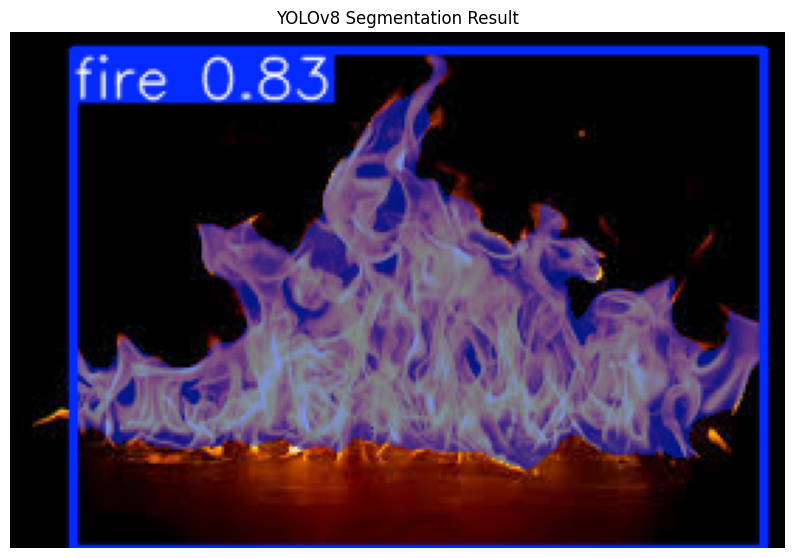

In [ ]:
# Get first result
result = results[0]

# This automatically draws boxes, labels, and segmentation masks
result_image = result.plot()

# Convert BGR to RGB for matplotlib
result_image_rgb = cv2.cvtColor(result_image, cv2.COLOR_BGR2RGB)

plt.figure(figsize=(10, 10))
plt.imshow(result_image_rgb)
plt.axis("off")
plt.title("YOLOv8 Segmentation Result")
plt.show()